# Permutation Feature Importance

**Family:** Machine learning &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Machine learning:* Evaluate and explain fitted models: classification performance, calibration, learning curves, residuals, feature importance and feature effects.

## Design purpose

Ranks features by how much a model's held-out performance drops when that feature's values are randomly shuffled. Box plots over many shuffles show both the importance and its uncertainty.

## When to use

- Rank the features any fitted model relies on (model-agnostic)
- Compare importance on held-out data rather than training data
- Show that some "important-looking" features are indistinguishable from zero

## Avoid when

- Features are strongly correlated (shuffling one leaves its twin, so both look unimportant)
- You need the direction of an effect (use SHAP or partial dependence)

## Alternatives

- SHAP summary (direction and per-case detail)
- Impurity-based importance (fast but biased towards high-cardinality features)

## Design tips

- Compute on a test set, not the training set
- Show the spread over repeats, not just a single bar
- Draw the zero line; boxes crossing zero are not reliably important

## Example

A random forest classifying wine cultivar in the real UCI Wine dataset (load_wine), with importance measured as the drop in test-set accuracy over 30 shuffles of each feature.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from sklearn.datasets import load_wine
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

### Data

In [2]:
wine = load_wine(as_frame=True)
X_tr, X_te, y_tr, y_te = train_test_split(wine.data, wine.target, test_size=0.35,
                                          stratify=wine.target, random_state=1)
rf = RandomForestClassifier(n_estimators=300, max_features=2, random_state=0).fit(X_tr, y_tr)
print(f"Test accuracy: {rf.score(X_te, y_te):.3f}")
res = permutation_importance(rf, X_te, y_te, n_repeats=30, random_state=0)
imp = pd.DataFrame(res.importances.T, columns=X_te.columns)
order = imp.median().sort_values().index
imp[order[::-1]].median().round(3)

Test accuracy: 1.000


color_intensity                 0.063
proline                         0.040
flavanoids                      0.024
alcohol                         0.016
od280/od315_of_diluted_wines    0.000
hue                             0.000
proanthocyanins                 0.000
nonflavanoid_phenols            0.000
total_phenols                   0.000
magnesium                       0.000
alcalinity_of_ash               0.000
ash                             0.000
malic_acid                      0.000
dtype: float64

### Plot

/var/folders/2q/sq_5xvg16ds08bkpx3ll0pxw0000gn/T/ipykernel_33888/3700225104.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([imp[c] for c in order], vert=False, widths=0.6, patch_artist=True,


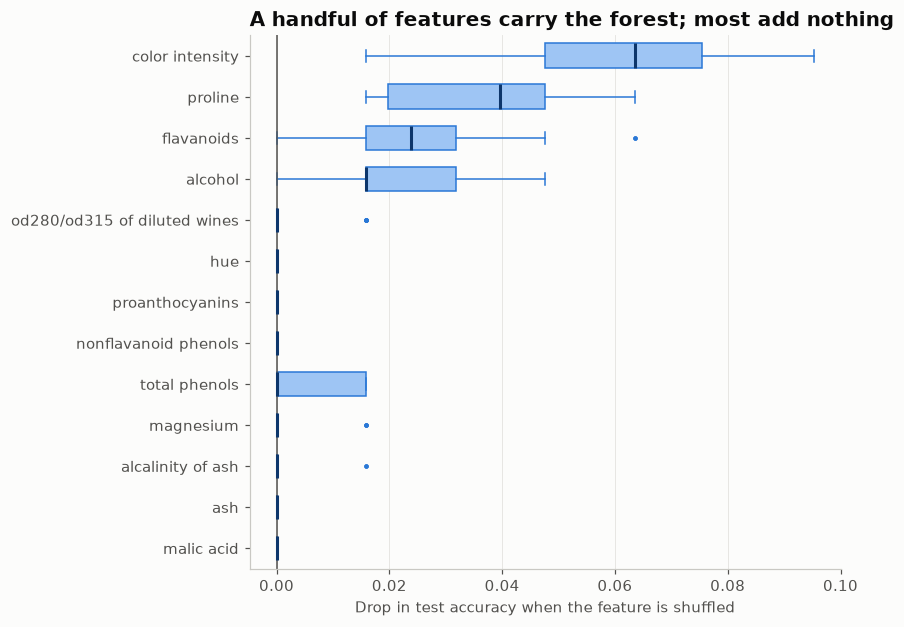

In [3]:
fig, ax = plt.subplots(figsize=(8, 5.8))
ax.boxplot([imp[c] for c in order], vert=False, widths=0.6, patch_artist=True,
           boxprops=dict(facecolor="#9ec5f4", edgecolor=PALETTE[0]),
           medianprops=dict(color="#0d366b", linewidth=2),
           whiskerprops=dict(color=PALETTE[0]), capprops=dict(color=PALETTE[0]),
           flierprops=dict(marker="o", markersize=3, markerfacecolor=PALETTE[0], markeredgecolor="none"))
ax.set_yticks(range(1, len(order) + 1), [c.replace("_", " ") for c in order])
ax.axvline(0, color="#52514e", lw=1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Drop in test accuracy when the feature is shuffled")
ax.set_title("A handful of features carry the forest; most add nothing")
fig.tight_layout()
plt.show()

## How to read it

Shuffling color intensity costs the most accuracy, followed by proline, flavanoids, alcohol and (weakly) total phenols, so the forest relies on these few. Most of the other features sit on zero: thanks to redundancy among the wine measurements, shuffling any one of them alone does not measurably hurt the model.

---
Standalone script: [`permutation_importance.py`](permutation_importance.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)